# Local debugging with a planetary map

- Thanks for the great example [Djenk Ivanov Orbit Wars | Agent OW-Proto | Passed 1,000 🥳](https://www.kaggle.com/code/djenkivanov/orbit-wars-agent-ow-proto-passed-1-000?scriptVersionId=316833310)

What else has been done:

-  The example has been translated into OOP technology. Dead lines removed. The algorithm itself has not changed.

-  The `agent` function is structured and divided into submethods.

- Added a planetary map, which is saved before each step to a file for immediate analysis before debugging.

- The map shows the planet identifiers. The sun displays each player's current score.

- The notebook was tested on a local computer with the current Docker.



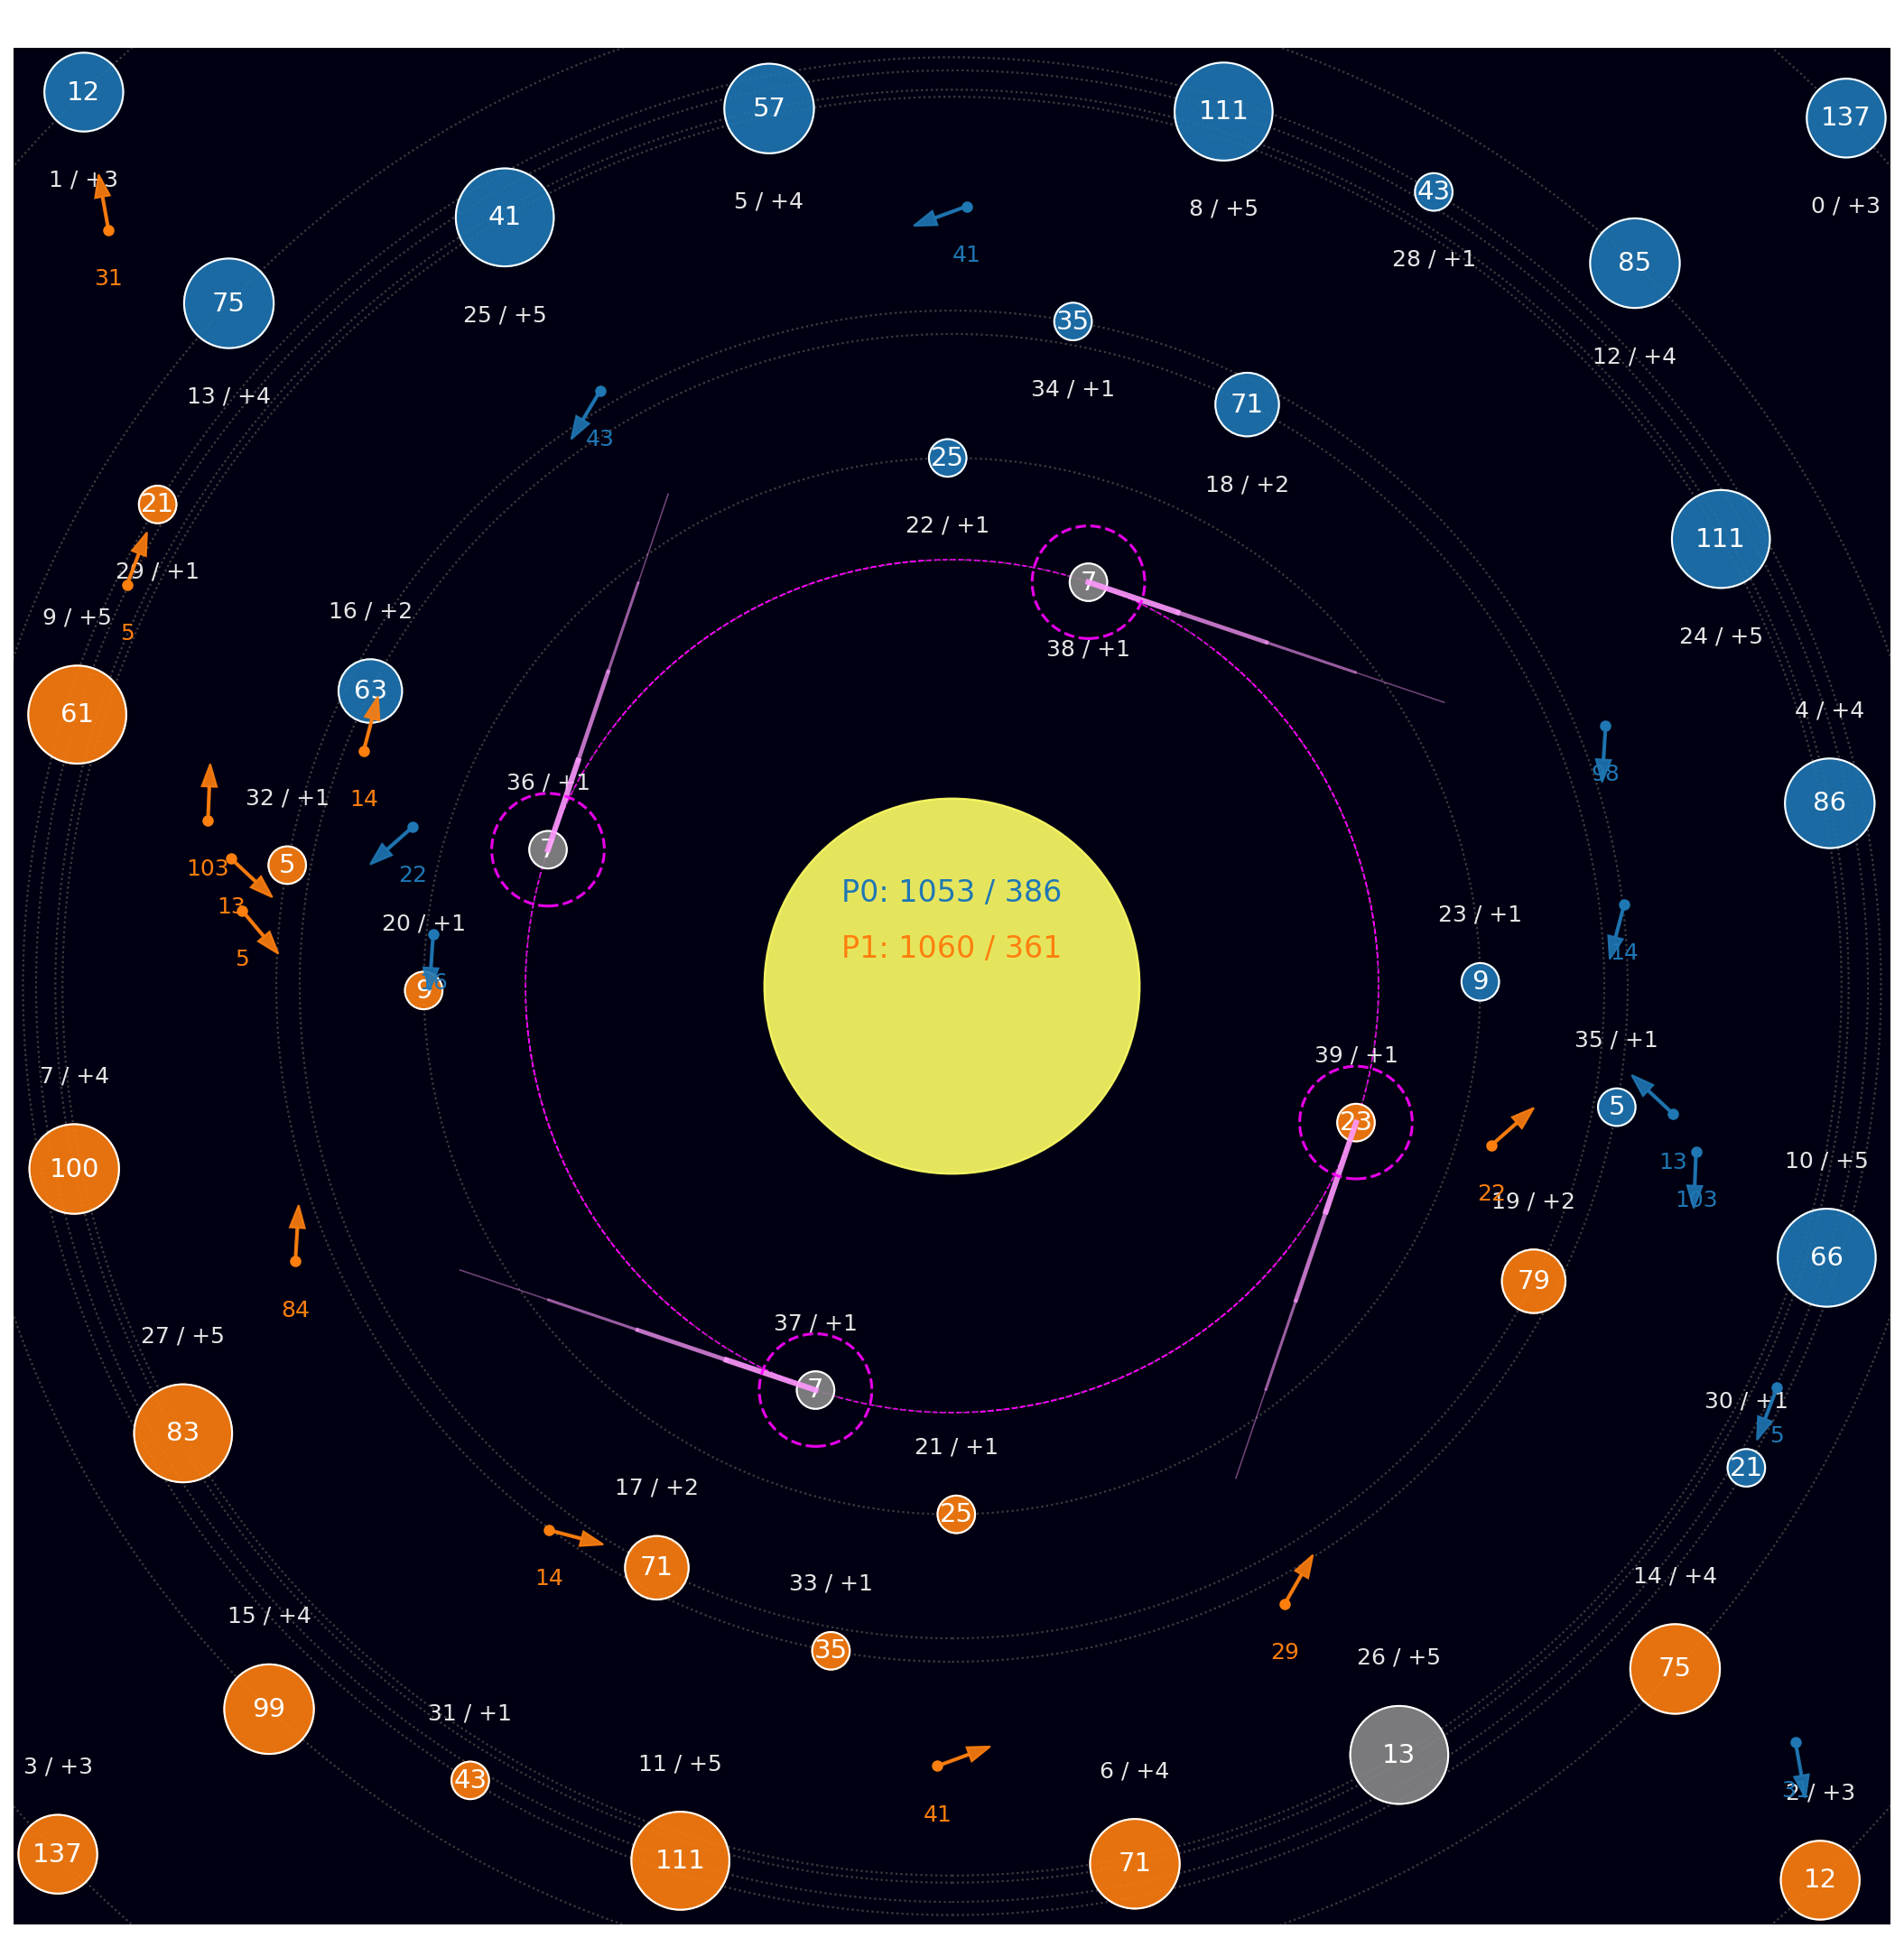

In [1]:
import subprocess; subprocess.run(f"pip install -U 'kaggle-environments>=1.28.0'", shell=True, check=True)


CompletedProcess(args="pip install -U 'kaggle-environments>=1.28.0'", returncode=0)

In [2]:
import math
import matplotlib.pyplot as plt
import kaggle_environments.envs.orbit_wars.orbit_wars as ow
import matplotlib
matplotlib.use('Agg') 

PLAYER_COLORS = {
    -1: "#888888",
     0: "#1f77b4",
     1: "#ff7f0e",
     2: "#2ca02c",
     3: "#d62728",
}

def draw_orbit_wars(obs, title=None, figsize=(18, 18)):
    planets = [ow.Planet(*p) for p in obs.get("planets", [])]
    fleets = [ow.Fleet(*f)  for f in obs.get("fleets", [])]
    player_id = obs.get("player", None)
    comet_planet_ids = set(obs.get("comet_planet_ids", []))
    angular_velocity = obs.get("angular_velocity", 0.0)
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect("equal")
    ax.set_facecolor("#000012")
    ax.grid(color="#222222", linestyle="--", linewidth=0.3, alpha=0.4)
    # Sun
    sun_x, sun_y, sun_r = 50, 50, 10
    sun = plt.Circle((sun_x, sun_y), sun_r, color="#ffff66", alpha=0.9, zorder=1)
    ax.add_patch(sun)
    # Orbits of the planets (circles)
    for p in planets:
        r = math.sqrt((p.x - sun_x)**2 + (p.y - sun_y)**2)
        if r > 0:
            orbit = plt.Circle(
                (sun_x, sun_y),
                r,
                color="#444444",
                fill=False,
                linestyle=":",
                alpha=0.4,
                zorder=0
            )
            ax.add_patch(orbit)
    # Elliptical approximation of comet trajectories + tails
    comet_traj_steps = 40
    comet_traj_dt = 1
    for p in planets:
        if p.id not in comet_planet_ids:
            continue
        r = math.sqrt((p.x - sun_x)**2 + (p.y - sun_y)**2)
        if r == 0:
            continue
        angle_now = math.atan2(p.y - sun_y, p.x - sun_x)
        xs, ys = [], []
        for k in range(-comet_traj_steps, comet_traj_steps + 1):
            angle_k = angle_now + angular_velocity * k * comet_traj_dt
            base_x = sun_x + r * math.cos(angle_k)
            base_y = sun_y + r * math.sin(angle_k)
            rx = base_x - sun_x
            ry = base_y - sun_y
            rad_len = math.hypot(rx, ry)
            if rad_len == 0:
                xs.append(base_x)
                ys.append(base_y)
                continue
            ux = rx / rad_len
            uy = ry / rad_len
            tx = -uy
            ty = ux
            ellipse_factor = 1.3
            ex = base_x + (ellipse_factor - 1.0) * tx * (r * 0.1)
            ey = base_y + (ellipse_factor - 1.0) * ty * (r * 0.1)
            xs.append(ex)
            ys.append(ey)
        ax.plot(
            xs, ys,
            color="#ff00ff",
            linestyle="--",
            linewidth=0.8,
            alpha=0.9,
            zorder=2
        )
        # Tail of 4 segments
        direction = 1 if angular_velocity >= 0 else -1
        tangent_angle = angle_now + direction * math.pi / 2
        total_tail_len = 20.0
        segments = 4
        segment_len = total_tail_len / segments
        tail_x0, tail_y0 = p.x, p.y
        for i in range(segments):
            width = 3.0 * (1.0 - i / segments)
            dx = -math.cos(tangent_angle) * segment_len
            dy = -math.sin(tangent_angle) * segment_len
            tail_x1 = tail_x0 + dx
            tail_y1 = tail_y0 + dy
            ax.plot(
                [tail_x0, tail_x1],
                [tail_y0, tail_y1],
                color="#ff99ff",
                linewidth=width,
                alpha=0.9 - 0.15 * i,
                zorder=6
            )
            tail_x0, tail_y0 = tail_x1, tail_y1
    # Planets
    for p in planets:
        base_color = PLAYER_COLORS.get(p.owner, "#ffffff")
        planet_disc = plt.Circle(
            (p.x, p.y),
            p.radius,
            color=base_color,
            alpha=0.9,
            zorder=3
        )
        ax.add_patch(planet_disc)
        outline = plt.Circle(
            (p.x, p.y),
            p.radius,
            fill=False,
            edgecolor="white",
            linewidth=1.0,
            zorder=4
        )
        ax.add_patch(outline)
        ax.text(
            p.x, p.y,
            str(p.ships),
            color="white",
            ha="center", va="center",
            fontsize=14,
            zorder=5
        )
        top_threshold = 70
        bottom_threshold = 30
        label_text = f"{p.id} / +{p.production}"
        if p.y >= top_threshold:
            ax.text(
                p.x, p.y - (p.radius + 2),
                label_text,
                color="white",
                ha="center", va="top",
                fontsize=12,
                alpha=0.9,
                zorder=5
            )
        elif p.y <= bottom_threshold:
            ax.text(
                p.x, p.y + (p.radius + 2),
                label_text,
                color="white",
                ha="center", va="bottom",
                fontsize=12,
                alpha=0.9,
                zorder=5
            )
        else:
            ax.text(
                p.x, p.y + (p.radius + 2),
                label_text,
                color="white",
                ha="center", va="bottom",
                fontsize=12,
                alpha=0.9,
                zorder=5
            )
        if p.id in comet_planet_ids:
            comet_ring = plt.Circle(
                (p.x, p.y),
                p.radius + 2,
                fill=False,
                edgecolor="#ff00ff",
                linewidth=1.5,
                linestyle="--",
                alpha=0.9,
                zorder=7
            )
            ax.add_patch(comet_ring)
    # Fleets
    for f in fleets:
        color = PLAYER_COLORS.get(f.owner, "#ffffff")
        ax.scatter(f.x, f.y, s=25, color=color, zorder=7)
        dx = math.cos(f.angle)
        dy = math.sin(f.angle)
        L = 3
        ax.arrow(
            f.x, f.y,
            dx * L, dy * L,
            width=0.1,
            head_width=0.8,
            head_length=1.2,
            length_includes_head=True,
            shape='full',
            overhang=0.0,
            color=color,
            alpha=0.9,
            zorder=7
        )
        ax.text(
            f.x, f.y - 2,
            str(f.ships),
            color=color,
            ha="center", va="top",
            fontsize=12,
            zorder=8
        )
    # Counting players' points and bringing them to the sun
    planet_scores = {}
    fleet_scores = {}
    for owner in range(4):
        planet_scores[owner] = sum(p.ships for p in planets if p.owner == owner)
        fleet_scores[owner] = sum(f.ships for f in fleets if f.owner == owner)
    # We write on the sun one line per player
    sun_lines = []
    for owner in range(4):
        if planet_scores[owner] == 0 and fleet_scores[owner] == 0:
            continue
        line = f"P{owner}: {planet_scores[owner]} / {fleet_scores[owner]}"
        sun_lines.append((owner, line))
    # Vertical placement inside/near the sun
    if sun_lines:
        base_y = sun_y + sun_r - 5  # just above the center
        line_spacing = 3
        for idx, (owner, text) in enumerate(sun_lines):
            y = base_y - idx * line_spacing
            ax.text(
                sun_x, y,
                text,
                color=PLAYER_COLORS.get(owner, "white"),
                ha="center", va="center",
                fontsize=16,
                zorder=10
            )
    # Headline
    if title is None:
        if player_id is not None:
            title = f"Orbit Wars – player {player_id}, step={obs.get('step', '?')}"
        else:
            title = "Orbit Wars"
    ax.set_title(title, color="white", fontsize=16)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    #plt.show()
    # Saving to a file (the format is determined by the extension)
    plt.savefig(f"/kaggle/working/orbit-wars-{obs.step}.png", dpi=150, bbox_inches='tight') 
    plt.close()


Loading environment cabt failed: dlopen(/Users/wang/anaconda3/envs/torch-gpu/lib/python3.12/site-packages/kaggle_environments/envs/cabt/cg/libcg.so, 0x0006): tried: '/Users/wang/anaconda3/envs/torch-gpu/lib/python3.12/site-packages/kaggle_environments/envs/cabt/cg/libcg.so' (slice is not valid mach-o file), '/System/Volumes/Preboot/Cryptexes/OS/Users/wang/anaconda3/envs/torch-gpu/lib/python3.12/site-packages/kaggle_environments/envs/cabt/cg/libcg.so' (no such file), '/Users/wang/anaconda3/envs/torch-gpu/lib/python3.12/site-packages/kaggle_environments/envs/cabt/cg/libcg.so' (slice is not valid mach-o file)
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO: Successfully loaded OpenSpiel environments: 23.
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_amazons
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_backgammon
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_checkers
[kaggle_environm

In [3]:
import sys, math, json, traceback
import kaggle_environments.envs.orbit_wars.orbit_wars as ow
from kaggle_environments.envs.orbit_wars.orbit_wars import Planet

class OrbitWarsAgent():
    def __init__(self):
        self.fleet_trajectories = []
        self.reinforcement_trajectories = []
        self.moving_planets = []
        self.planets_coords = {}
        self.MAX_SPEED = 6.0
        self.CENTER_X = 50
        self.CENTER_Y = 50
        self.planet_log = {}
        self.FORMULA_DIST = 100.0
        self.FORMULA_PROD_MULT = 15.0
        self.FORMULA_ENEMY_BONUS_MULT = 10.0
        self.FORMULA_TOTAL_SHIPS_PERCENT = 0.7
        self.MIN_SHIPS_MINE_ATTACK = 5
        self.MIN_SHIPS_TARGET_COOP_ATTACK = 20
        self.COOP_PLANET_CAP = 8
    
    def get_custom_score(self, m, t):
        dist = math.sqrt((m.x - t.x)**2 + (m.y - t.y)**2)
        min_ships = t.ships + 1
        fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(max(1, min_ships)) / math.log(1000)) ** 1.5
        eta = dist / fleet_speed
        enemy_produced = 0
        enemy_bonus = 0
        if t.owner != -1:
            enemy_produced = eta * t.production
            enemy_bonus = t.production
        total_ships = min_ships + enemy_produced
        # + close targets
        # + high production
        # + if planet is owned by enemy (capturing planet is more valuable because we gain ships, they lose ships)
        # - lot of enemies and enemies produced by arrival
        # - slow arrivals
        return (
            (self.FORMULA_DIST - dist)
            + (self.FORMULA_PROD_MULT * t.production)
            + (self.FORMULA_ENEMY_BONUS_MULT * enemy_bonus)
            - (self.FORMULA_TOTAL_SHIPS_PERCENT * total_ships)
            - (2 * eta)
        )

    def get_planets_under_attack(self, mine, fleets, player, vel):
        mov_pl_traj = {}
        under_attack = {}
        seen = set()
        fleets = [f for f in fleets if f.owner != player]
        for m in mine:
            if m.id in self.moving_planets:
                mov_pl_traj[m.id] = self.get_planet_trajectories(m, vel)
        for f in fleets:
            fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(f.ships) / math.log(1000)) ** 1.5
            prev_x = f.x
            prev_y = f.y
            for tick in range(1, 61):
                next_x = f.x + math.cos(f.angle) * fleet_speed * tick
                next_y = f.y + math.sin(f.angle) * fleet_speed * tick
                for m in mine:
                    if m.id in self.moving_planets:
                        m_x, m_y = mov_pl_traj[m.id][tick-1] # tick is 1 based, index 0 based, so -1
                    else:
                        m_x, m_y = m.x, m.y
                    if self.collides(prev_x, prev_y, next_x, next_y, m_x, m_y, m.radius): 
                        if (m.id, f.id) not in seen:
                            if m.id not in under_attack:
                                under_attack[m.id] = {
                                    "planet": m,
                                    "fleets": []
                                }
                            under_attack[m.id]["fleets"].append({
                                "fleet": f,
                                "arrive_tick": tick
                            })
                            seen.add((m.id, f.id))
                prev_x = next_x
                prev_y = next_y
        return under_attack
    
    def sun_collision(self, m, fleet_speed, angle, ticks=61):
        prev_x = m.x
        prev_y = m.y
        for tick in range(1, ticks):
            x = m.x + math.cos(angle) * fleet_speed * tick
            y = m.y + math.sin(angle) * fleet_speed * tick
            if self.collides(prev_x, prev_y, x, y, 50, 50, 10):
                return True
            prev_x = x
            prev_y = y
        return False

    def calculate_req_ships_moving(self, attacking_planets, t, base_ships, vel):
        MAX_SPEED = 6.0
        required_ships = base_ships
        planet_trajectories = self.get_planet_trajectories(t, vel)
        for _ in range(3):
            remainder = required_ships
            max_tick = 0
            for a_p in attacking_planets:
                p = a_p["planet"]
                p_ships = min(a_p["ships"], remainder)
                if p_ships > 0:
                    p_ships = min(a_p["ships"], max(p_ships, self.MIN_SHIPS_MINE_ATTACK))
                if p_ships <= 0:
                    continue
                fleet_speed = 1.0 + (MAX_SPEED - 1.0) * (math.log(max(1, p_ships)) / math.log(1000)) ** 1.5
                found_tick = 0
                for tick, (tx, ty) in enumerate(planet_trajectories, start=1):
                    dist = math.sqrt((p.x - tx)**2 + (p.y - ty)**2)
                    turns_to_arrive = math.floor(dist / fleet_speed)
                    if abs(turns_to_arrive - tick) <= 1:
                        found_tick = tick
                        break
                if found_tick > max_tick:
                    max_tick = found_tick
                remainder -= p_ships
            new_req = base_ships + (max_tick * t.production)
            if new_req == required_ships:
                break
            required_ships = new_req
        return required_ships

    def calculate_req_ships(self, attacking_planets, t, base_ships):
        required_ships = base_ships
        for _ in range(3):
            remainder = required_ships
            max_tick = 0
            for a_p in attacking_planets:
                p = a_p["planet"]
                p_ships = min(a_p["ships"], remainder)
                if p_ships > 0:
                    p_ships = min(a_p["ships"], max(p_ships, self.MIN_SHIPS_MINE_ATTACK))
                if p_ships <= 0:
                    continue
                ships_for_speed = max(1, p_ships)
                fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(ships_for_speed) / math.log(1000)) ** 1.5
                dist = math.sqrt((p.x - t.x)**2 + (p.y - t.y)**2)
                tick_arrival = math.floor(dist / fleet_speed)
                if tick_arrival > max_tick:
                    max_tick = tick_arrival
                remainder -= p_ships
            new_req = base_ships + (max_tick * t.production)
            if new_req == required_ships:
                break
            required_ships = new_req
        return required_ships

    @staticmethod
    def calculate_angle(m, t):
        return math.atan2(t.y - m.y, t.x - m.x)

    def find_angle_to_moving_planet(self, p, t, ships, vel):
        fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(ships) / math.log(1000)) ** 1.5
        planet_trajectories = self.get_planet_trajectories(t, vel)
        for tick, (tx, ty) in enumerate(planet_trajectories, start=1):
            dx = tx - p.x
            dy = ty - p.y
            dist_to_target = math.sqrt(dx**2 + dy**2) - p.radius
            travel_dist = fleet_speed * tick
            miss_dist = abs(travel_dist - dist_to_target)
            if miss_dist > t.radius:
                continue
            angle = math.atan2(dy, dx)
            if self.sun_collision(p, fleet_speed, angle):
                return None, None
            return angle, tick
        return None, None

    @staticmethod
    def collides(x1, y1, x2, y2, cx, cy, r):
        vec_x = x2 - x1
        vec_y = y2 - y1
        vec_to_cx = cx - x1
        vec_to_cy = cy - y1
        vec_length_sq = vec_x**2 + vec_y**2
        if vec_length_sq == 0:
            dx = x1 - cx
            dy = y1 - cy
            return dx**2 + dy**2 <= r**2
        closest_point = (vec_to_cx * vec_x + vec_to_cy * vec_y) / vec_length_sq
        closest_point = max(0, min(1, closest_point))
        closest_x = x1 + closest_point * vec_x
        closest_y = y1 + closest_point * vec_y
        dx = closest_x - cx
        dy = closest_y - cy
        return dx**2 + dy**2 <= r**2

    @staticmethod
    def get_closest_planets_to_target(mine, t):
        planets = []
        for m in mine:
            dist = math.sqrt((m.x - t.x)**2 + (m.y - t.y)**2)
            planets.append((m, dist))
        planets = sorted(planets, key=lambda k: k[1])
        return planets

    def update_fleet_trajectories(self, fleets):
        for f_t in self.fleet_trajectories[:]:
            found = False
            for f in fleets:
                if f.from_planet_id == f_t["mine"].id and abs(f.angle - f_t["angle"]) < 1e-3:
                    found = True
                    break
            if found:
                f_t["arrive_tick"] = max(0, f_t["arrive_tick"] - 1)
            if not found:
                self.fleet_trajectories.remove(f_t)

    def update_reinforcement_trajectories(self, planets):
        planet_ids = {p.id for p in planets}
        for r_t in self.reinforcement_trajectories[:]:
            r_t["arrive_tick"] -= 1
            if r_t["arrive_tick"] <= 0:
                self.reinforcement_trajectories.remove(r_t)
                continue

    @staticmethod
    def get_planet_trajectories(p, vel):
        planet_trajectories = []
        angle = math.atan2(p.y - 50, p.x - 50)
        r = math.sqrt((p.x - 50)**2 + (p.y - 50)**2)
        for tick in range(1, 61): # max 60 ticks
            angle_t = angle + vel * tick
            x_t = 50 + r * math.cos(angle_t)
            y_t = 50 + r * math.sin(angle_t)
            planet_trajectories.append((x_t, y_t))
        return planet_trajectories

    def fill_moving_planets(self, obs):
        self.moving_planets = []
        planets = [ow.Planet(*p) for p in obs.get("planets", [])]
        initial_by_id = {i[0]: ow.Planet(*i) for i in obs.get("initial_planets", [])}
        for p in planets:
            i = initial_by_id[p.id]
            if (p.x, p.y) != (i.x, i.y):
                if p.id not in self.moving_planets:
                    self.moving_planets.append(p.id)

    def get_reinforcement_plans(self, mine, under_attack):
        reinforcement_plans = {}
        for p in mine:
            if p.id in under_attack:
                attacking_fleets = sorted(
                    under_attack[p.id]["fleets"],
                    key=lambda att: att["arrive_tick"]
                )
                incoming_reinforcements = sorted(
                    [r for r in self.reinforcement_trajectories if r["target"].id == p.id],
                    key=lambda r: r["arrive_tick"]
                )
                p_available_ships = p.ships
                previous_tick = 0
                r_idx = 0
                for att in attacking_fleets:
                    att_arrive_tick = att["arrive_tick"]
                    p_available_ships += (att_arrive_tick - previous_tick) * p.production
                    while (
                        r_idx < len(incoming_reinforcements)
                        and incoming_reinforcements[r_idx]["arrive_tick"] <= att_arrive_tick
                    ):
                        p_available_ships += incoming_reinforcements[r_idx]["total_ships"]
                        r_idx += 1
                    enemy_ships = att["fleet"].ships
                    p_available_ships -= enemy_ships
                    previous_tick = att_arrive_tick
                    if p_available_ships < 0:
                        reinforcements_needed = max(self.MIN_SHIPS_MINE_ATTACK, abs(p_available_ships))
                        reinforcement_plans[p] = {
                            "ships_needed": reinforcements_needed,
                            "needed_by_tick": att_arrive_tick
                        }
                        break
        return reinforcement_plans

    def init_planet_log(self, all_planets, owner_player, under_attack):
        self.planet_log = {}
        for tpl_planet in all_planets:
            self.planet_log[tpl_planet.id] = dict(
                production=tpl_planet.production,
                owner=tpl_planet.owner,
                radius=tpl_planet.radius,
                ships=tpl_planet.ships,
                x=tpl_planet.x,
                y=tpl_planet.y,
                mine=tpl_planet.owner==owner_player,
                reinforcement_trajectories=[],
                under_attack=under_attack.get(tpl_planet.id, {}).get('fleets', [])
            )

    def reinforcement_planets(self, obs, mine_planets, under_attack, moves):
        exhausted_planets_id = set()
        reinforcement_plans = self.get_reinforcement_plans(mine_planets, under_attack)
        for p, plan in reinforcement_plans.items():
            already_reinforced = any(
                r["target"].id == p.id and r["arrive_tick"] >= 0
                for r in self.reinforcement_trajectories
            )
            self.planet_log[p.id]['already_reinforced'] = already_reinforced
            if already_reinforced:
                continue   
            ships_needed = plan["ships_needed"]
            needed_by_tick = plan["needed_by_tick"]
            nearest_planets = self.get_closest_planets_to_target(mine_planets, p)
            for row in nearest_planets:
                p_np, _ = row
                if p_np.id == p.id:
                    continue
                elif p_np.id in exhausted_planets_id:
                    self.planet_log[p.id]['exhausted_planet'] = True
                    continue
                p_np_available_ships = p_np.ships
                self.planet_log[p.id]['p_np_available_ships'] = p_np_available_ships
                reserved_reinforcement_ships = sum(
                    r["total_ships"]
                    for r in self.reinforcement_trajectories
                    if r["mine"].id == p_np.id
                )
                p_np_available_ships -= reserved_reinforcement_ships
                self.planet_log[p.id]['reserved_reinforcement_ships'] = reserved_reinforcement_ships
                if p_np.id in under_attack:
                    enemy_ships = sum(
                        att["fleet"].ships
                        for att in under_attack[p_np.id]["fleets"]
                    )
                    self.planet_log[p.id]['enemy_ships'] = enemy_ships
                    p_np_available_ships = max(0, p_np_available_ships - enemy_ships)
                sent_reinforcements = max(self.MIN_SHIPS_MINE_ATTACK, ships_needed)
                if p_np_available_ships < sent_reinforcements:
                    self.planet_log[p.id]['few_ships_for_support'] = True
                    continue
                angle_np = None
                if p.id not in self.moving_planets:
                    angle_np = math.atan2(p.y - p_np.y, p.x - p_np.x)
                    fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(sent_reinforcements) / math.log(1000)) ** 1.5                
                    dist = math.sqrt((p.x - p_np.x)**2 + (p.y - p_np.y)**2)
                    arrive_tick = math.floor(dist / fleet_speed)
                    if arrive_tick > needed_by_tick:
                        self.planet_log[p.id]['to_arrive_tick_more_is_necessary'] = True
                        continue
                else:
                    angle_np, arrive_tick = self.find_angle_to_moving_planet(p_np, p, sent_reinforcements, obs.angular_velocity)
                    self.planet_log[p.id]['angle_np'] = angle_np
                    self.planet_log[p.id]['arrive_tick'] = arrive_tick
                if angle_np is None or arrive_tick is None:
                    self.planet_log[p.id]['not_angle_np_or_arrive_tick'] = True
                    continue
                moves.append([p_np.id, angle_np, sent_reinforcements])
                exhausted_planets_id.add(p_np.id)
                self.reinforcement_trajectories.append({
                    "mine": p_np,
                    "target": p,
                    "angle": angle_np,
                    "total_ships": sent_reinforcements,
                    "arrive_tick": arrive_tick
                })
                self.planet_log[p.id]['reinforcement_trajectories'].append({
                    "mine": p_np.id,
                    "angle": angle_np,
                    "total_ships": sent_reinforcements,
                    "arrive_tick": arrive_tick
                })
                break
        return exhausted_planets_id

    def get_candidate_targets(self, my_planet, target_planets, comet_planet_ids):
        candidate_targets = []
        for t in target_planets:
            if t.id in comet_planet_ids:
                continue
            score = self.get_custom_score(my_planet, t)
            candidate_targets.append((my_planet, t, score))
        candidate_targets = sorted(candidate_targets, key=lambda x: x[2], reverse=True)
        return candidate_targets
    
    def safe_nearest_planets(self, my_planet, nearest_planets, under_attack, exhausted_planets_id):
        safe_nearest_planets = []
        for p, dist in nearest_planets: # check which planets are fit to attack and are not vulnerable
            if p.id == my_planet.id or p.id in exhausted_planets_id:
                continue
            available_ships = p.ships
            if p.id in under_attack:
                enemy_ships = sum(
                    att["fleet"].ships 
                    for att in under_attack[p.id]["fleets"]
                )
                available_ships = max(0, p.ships - enemy_ships)
            if available_ships < self.MIN_SHIPS_MINE_ATTACK:
                continue
            safe_nearest_planets.append((p, dist, available_ships))
        return safe_nearest_planets
    
    def get_total_ships_for_single_moving_planet(self, obs, my_planet, t, base_ships, m_available_ships):
        total_ships = base_ships
        for _ in range(3):
            angle, arrive_tick = self.find_angle_to_moving_planet(my_planet, t, total_ships, obs.angular_velocity)
            if angle is None:
                break
            if t.owner != -1:
                new_total_ships = base_ships + arrive_tick * t.production
            else:
                new_total_ships = base_ships
            if new_total_ships > m_available_ships:
                angle = None
                break
            if new_total_ships == total_ships:
                break
            total_ships = new_total_ships
        return total_ships, arrive_tick, angle
    
    def get_total_ships_for_single_static_planet(self, my_planet, t, base_ships, m_available_ships):
        total_ships = base_ships
        dist = math.sqrt((t.x - my_planet.x)**2 + (t.y - my_planet.y)**2)
        fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(max(1, total_ships)) / math.log(1000)) ** 1.5
        arrive_tick = math.floor(dist / fleet_speed)
        if t.owner != -1: # single static owned
            for _ in range(3):
                fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(max(1, total_ships)) / math.log(1000)) ** 1.5
                turns_to_arrive = math.floor(dist / fleet_speed)
                extra_ships = turns_to_arrive * t.production
                new_total_ships = base_ships + extra_ships
                if new_total_ships > m_available_ships:
                    arrive_tick = None
                    break
                arrive_tick = turns_to_arrive
                if new_total_ships == total_ships:
                    break
                total_ships = new_total_ships
            #extra_ships = total_ships - base_ships
        #else:
        #    extra_ships = 0
        return total_ships, arrive_tick  #, extra_ships
    
    def get_remainder_coop_static_unowned(self, t, base_ships, attacking_planets):
        remainder = base_ships
        planned = []
        for a_p in attacking_planets:
            p = a_p["planet"]
            p_ships = min(a_p["ships"], remainder)
            if p_ships > 0:
                p_ships = min(a_p["ships"], max(p_ships, self.MIN_SHIPS_MINE_ATTACK))
            if p_ships <= 0:
                continue
            angle = self.calculate_angle(p, t)
            dist = math.sqrt((p.x - t.x)**2 + (p.y - t.y)**2)
            fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(p_ships) / math.log(1000)) ** 1.5
            arrive_tick = math.floor(dist / fleet_speed)
            collides_sun = self.sun_collision(p, fleet_speed=fleet_speed, angle=angle)
            if collides_sun:
                break
            remainder -= p_ships
            planned.append([p, angle, p_ships, arrive_tick])
        return remainder, planned

    def get_remainder_coop_static_owned(self, t, required_ships, attacking_planets):
        remainder = required_ships
        planned = []
        for a_p in attacking_planets:
            p = a_p["planet"]
            p_ships = min(a_p["ships"], remainder)
            if p_ships > 0:
                p_ships = min(a_p["ships"], max(p_ships, self.MIN_SHIPS_MINE_ATTACK))
            if p_ships <= 0:
                continue
            angle = self.calculate_angle(p, t)
            dist = math.sqrt((p.x - t.x)**2 + (p.y - t.y)**2)
            fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(p_ships) / math.log(1000)) ** 1.5
            arrive_tick = math.floor(dist / fleet_speed)
            collides_sun = self.sun_collision(p, fleet_speed=fleet_speed, angle=angle)
            if collides_sun:
                continue
            remainder -= p_ships
            planned.append([p, angle, p_ships, arrive_tick])
        return remainder, planned
    
    def get_remainder_coop_moving_unowned(self, obs, t, base_ships, attacking_planets):
        remainder = base_ships
        planned = []
        for a_p in attacking_planets:
            p = a_p["planet"]
            p_ships = min(a_p["ships"], remainder)
            if p_ships > 0:
                p_ships = min(a_p["ships"], max(p_ships, self.MIN_SHIPS_MINE_ATTACK))
            if p_ships <= 0:
                continue
            angle, arrive_tick = self.find_angle_to_moving_planet(p, t, p_ships, obs.angular_velocity)
            if angle is None or arrive_tick is None:
                continue
            planned.append([p, angle, p_ships, arrive_tick])
            remainder -= p_ships
        return remainder, planned
    
    def get_remainder_coop_moving_owned(self, obs, t, required_ships, attacking_planets):
        remainder = required_ships
        planned = []
        for a_p in attacking_planets:
            p = a_p["planet"]
            p_ships = min(a_p["ships"], remainder)
            if p_ships > 0:
                p_ships = min(a_p["ships"], max(p_ships, self.MIN_SHIPS_MINE_ATTACK))   
            if p_ships <= 0:
                continue
            #fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(max(1, p_ships)) / math.log(1000)) ** 1.5
            angle, arrive_tick = self.find_angle_to_moving_planet(p, t, p_ships, obs.angular_velocity)
            if angle is None or arrive_tick is None:
                continue
            remainder -= p_ships
            planned.append([p, angle, p_ships, arrive_tick])
        return remainder, planned
    
    def add_moves_from_planned(self, planned, t, moves, exhausted_planets_id):
        for move in planned:
            self.fleet_trajectories.append({
                "mine": move[0],
                "target": t,
                "angle": move[1],
                "total_ships": move[2],
                "arrive_tick": move[3]
            })
            exhausted_planets_id.add(move[0].id)
            move[0] = move[0].id
            moves.append(move)

    def base_agent(self, obs):
        moves = []
        if obs.step <= 2:
            if obs.step < 2:
                return moves
            self.fill_moving_planets(obs)
        all_planets = [ow.Planet(*p) for p in obs.get("planets", [])]
        owner_player = obs.get("player", [])
        target_planets = [p for p in all_planets if p.owner != owner_player]
        if not target_planets:
            return []
        mine_planets = [p for p in all_planets if p.owner == owner_player]
        my_player = obs.get("player", -2)
        fleets = [ow.Fleet(*f) for f in obs.get("fleets", [])]
        self.update_fleet_trajectories(fleets)
        self.update_reinforcement_trajectories(all_planets)
        comet_planet_ids = obs.get("comet_planet_ids", [])    
        under_attack = self.get_planets_under_attack(mine_planets, fleets, my_player, obs.angular_velocity)
        self.init_planet_log(all_planets, owner_player, under_attack)
        exhausted_planets_id = self.reinforcement_planets(obs, mine_planets, under_attack, moves)
        for m in sorted(mine_planets, key=lambda p: p.ships, reverse=True):
            if m.id in exhausted_planets_id:
                continue
            if m.ships < self.MIN_SHIPS_MINE_ATTACK:
                continue
            candidate_targets = self.get_candidate_targets(m, target_planets, comet_planet_ids)
            for m, t, s in candidate_targets[:3]:
                m_available_ships = m.ships
                if m.id in under_attack:
                    enemy_ships = sum(
                        att["fleet"].ships
                        for att in under_attack[m.id]["fleets"]
                    )
                    m_available_ships = max(0, m.ships - enemy_ships)
                if m_available_ships < self.MIN_SHIPS_MINE_ATTACK:
                    continue
                nearest_planets = self.get_closest_planets_to_target(mine_planets, t)
                safe_nearest_planets = self.safe_nearest_planets(m, nearest_planets, under_attack, exhausted_planets_id)
                owned_count = len(mine_planets)
                total_count = len(all_planets)
                en_route = 0
                if self.fleet_trajectories:
                    en_route = sum(
                        f["total_ships"]
                        for f in self.fleet_trajectories
                        if f["target"].id == t.id
                    )
                needed_now = t.ships + 1
                if t.owner != -1:
                    needed_now += 3 * t.production
                if owned_count < total_count * 0.75: # release all havoc when targets less than ~25%
                    if en_route >= needed_now:
                        continue
                base_ships = max(self.MIN_SHIPS_MINE_ATTACK, needed_now - en_route)
                #extra_ships = 0
                fleet_speed = 0
                angle = None
                arrive_tick = None
                if m_available_ships >= base_ships: # single attack
                    if t.id in self.moving_planets: # single moving planet
                        total_ships, arrive_tick, angle = self.get_total_ships_for_single_moving_planet(
                            obs, m, t, base_ships, m_available_ships)
                        #extra_ships = total_ships - base_ships
                    else: # single static planet
                        angle = self.calculate_angle(m, t) # single static unowned
                        if angle is None:
                            continue
                        total_ships, arrive_tick = self.get_total_ships_for_single_static_planet(
                            m, t, base_ships, m_available_ships)
                    if angle is not None and arrive_tick is not None:
                        fleet_speed = 1.0 + (self.MAX_SPEED - 1.0) * (math.log(max(1, total_ships)) / math.log(1000)) ** 1.5
                        collides_sun = self.sun_collision(m, fleet_speed, angle)
                        if collides_sun:
                            continue
                        moves.append([m.id, angle, total_ships])
                        exhausted_planets_id.add(m.id)
                        self.fleet_trajectories.append({
                            "mine": m,
                            "target": t,
                            "angle": angle,
                            "total_ships": total_ships,
                            "arrive_tick": arrive_tick
                        })
                elif m_available_ships < base_ships and len(mine_planets) > 1 and t.ships >= self.MIN_SHIPS_TARGET_COOP_ATTACK: # coop attack
                    accum = m_available_ships
                    attacking_planets = [{"planet": m, "ships": m_available_ships}]
                    coop_sent = False
                    for p, dist, p_available_ships in safe_nearest_planets:
                        if coop_sent:
                            break
                        attacking_planets.append({"planet": p, "ships": p_available_ships})
                        accum += p_available_ships
                        if len(attacking_planets) > self.COOP_PLANET_CAP:
                            break
                        if accum < base_ships:
                            continue
                        if t.id not in self.moving_planets: # coop static planet
                            if t.owner == -1: # coop static unowned
                                remainder, planned = self.get_remainder_coop_static_unowned(t, base_ships, attacking_planets)
                                if remainder > 0:
                                    continue
                                self.add_moves_from_planned(planned, t, moves, exhausted_planets_id)
                                coop_sent = True
                                break
                            else: # coop static owned
                                required_ships = self.calculate_req_ships(attacking_planets, t, base_ships)
                                if accum < required_ships: 
                                    continue
                                remainder, planned = self.get_remainder_coop_static_owned(t, required_ships, attacking_planets)
                                if remainder > 0:
                                    continue
                                self.add_moves_from_planned(planned, t, moves, exhausted_planets_id)
                                coop_sent = True
                                break
                        else: # coop moving planet
                            #planet_trajectories = self.get_planet_trajectories(t, obs.angular_velocity)
                            if t.owner == -1: # coop moving unowned
                                remainder, planned = self.get_remainder_coop_moving_unowned(obs, t, base_ships, attacking_planets)
                                if remainder > 0:
                                    continue
                                self.add_moves_from_planned(planned, t, moves, exhausted_planets_id)
                                coop_sent = True
                                break
                            else: # coop moving owned
                                required_ships = self.calculate_req_ships_moving(attacking_planets, t, base_ships, obs.angular_velocity)
                                if accum < required_ships:
                                    continue
                                remainder, planned = self.get_remainder_coop_moving_owned(obs, t, required_ships, attacking_planets)
                                if remainder > 0:
                                    continue
                                self.add_moves_from_planned(planned, t, moves, exhausted_planets_id)
                                coop_sent = True
                                break
        return moves

    def agent(self, obs, game_settings=None):
        # game_settings:
        # actTimeout = 1
        # agentTimeout = 2
        # cometSpeed = 4.0
        # episodeSteps = 500
        # runTimeout = 1200
        # seed = None
        # shipSpeed = 6.0
        if obs.step > 1:
            draw_orbit_wars(obs, title=f"Step {obs.step}")
        try:
            moves = self.base_agent(obs)
            #with open(f"/kaggle/working/planet_log-{obs.step}.jsonl", 'w', encoding='utf-8') as file_handle:
            #    file_handle.write(json.dumps(self.planet_log, ensure_ascii=False, indent=2))
            return moves
        except Exception as exc:
            exc_type, exc_value, exc_traceback = sys.exc_info(); print("".join(traceback.format_exception(exc_type, exc_value, exc_traceback)))
        return []

def make_agent():
    return OrbitWarsAgent().agent


In [4]:
import yaml, json, random, datetime as dt 
from pathlib import Path
from collections import defaultdict
from kaggle_environments import make
from statistics import mean
import importlib.util

class AppLogger(object):
    def init(self, fname=''):
        self.fname = fname
        self.orig_print = print
        return
    def printml(self, *args):
        toprint=''
        for arg in args:
            self.orig_print(arg)
            try:
                toprint += json.dumps(arg, indent=2) + "\n"
            except:
                toprint += f"{arg}"
        if self.fname:
            with open(self.fname, 'at') as f:
                f.write(f"{toprint}")
                f.flush

date_time_start = dt.datetime.now()
dt_start_ymd_hms = date_time_start.strftime("%Y.%m.%d_%H-%M-%S")
path_out = "/kaggle/working"
log = AppLogger()
log.init(f"{path_out}/LogFile-{dt_start_ymd_hms}.txt")
print = log.printml

AGENT_PATH = "/kaggle/code/2026-06-24 Orbit Wars/05 Agents"
game_agent_list = [
    [dict(module_name='main_01_djenk_ivanov_proto_passed_v19', agent_dir="2026-05-05 Djenk Ivanov - orbit-wars-agent-ow-proto-passed-1-000 v19 LB=1018.4")],
    # [dict(module_name='main_02_sigmaborov_reinforce_v02', agent_dir="2026-04-18 sigmaborov - lb-958-1-orbit-wars-2026-reinforce v02 LB=958.1")],
    # [dict(module_name='main_03_pascal_orbitwork_v14_01', agent_dir="2026-04-19 Pascal - orbitwork-v14 v01 LB=1037.3")],
    # [   
    #     dict(module_name='main_01_djenk_ivanov_proto_passed_v19', agent_dir="2026-05-05 Djenk Ivanov - orbit-wars-agent-ow-proto-passed-1-000 v19 LB=1018.4"),
    #     dict(module_name='main_02_sigmaborov_reinforce_v02', agent_dir="2026-04-18 sigmaborov - lb-958-1-orbit-wars-2026-reinforce v02 LB=958.1"),
    #     dict(module_name='main_03_pascal_orbitwork_v14_01', agent_dir="2026-04-19 Pascal - orbitwork-v14 v01 LB=1037.3")
    # ],
]

MATCH_TRIALS = 1
MY_PLAYER = 'My_Player'

def play_episode(game_agents):
    env = make("orbit_wars", debug=True)
    #env.reset()  # num_agents
    agent_list = [make_agent()]
    for game_agent in game_agents:
        # Creating a module specification
        module_name = game_agent['module_name']
        spec = importlib.util.spec_from_file_location(module_name, f"{AGENT_PATH}/{game_agent['agent_dir']}/main.py")
        module = importlib.util.module_from_spec(spec)
        # Add to system cache (optional, but recommended)
        #sys.modules[module_name] = module
        # Executing the module code to activate it
        spec.loader.exec_module(module)
        agent_list.append(module.agent)
    game_result = env.run(agent_list)
    final_step = env.steps[-1]
    result = []
    for player_data in final_step:
        observation = player_data.observation
        player_id = observation.player
        if player_data.reward == 1:
            print(f"Player={player_id}: reward=Winner, status={player_data.status}")
            result.append(dict(player_id=player_id, score=1.0))
        elif player_data.reward == 0:
            print(f"Player={player_id}: reward=Draw, status={player_data.status}")
            result.append(dict(player_id=player_id, score=0.5))
        else:
            result.append(dict(player_id=player_id, score=0.0))
    return result, len(env.steps)

def play_match(match_trials=MATCH_TRIALS):
    game_count = 0
    victory_all = defaultdict(float)
    for i, match_game_agents in enumerate(game_agent_list):
        victory = defaultdict(float)
        for j in range(match_trials):
            game_count += 1
            match_score, step_count = play_episode(match_game_agents)
            print(f"Trial {j+1}/{match_trials} steps={step_count} score={match_score}")
            for score_data in match_score:
                player_id = score_data['player_id']
                if player_id == 0:
                    module_name = MY_PLAYER
                else:
                    module_name = match_game_agents[player_id - 1]['module_name']
                victory[module_name] += score_data['score']
        print(f"{i+1} victory={victory}")
        for player_id, score in victory.items():
            victory_all[player_id] += score
    print(f"All={victory_all}")
    return victory_all[MY_PLAYER] / game_count

random.seed(0)
play_match()


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/code/2026-06-24 Orbit Wars/05 Agents/2026-05-05 Djenk Ivanov - orbit-wars-agent-ow-proto-passed-1-000 v19 LB=1018.4/main.py'